# The equations of linear elasticity

## The PDE Problem

The equations governing small elastic deformations of a body $\Omega$ can be written as

$$
\begin{aligned}
-\nabla \cdot \boldsymbol{\sigma}(\mathbf{u}) &= \mathbf{f} && \text{in } \Omega, \\
\boldsymbol{\sigma}(\mathbf{u}) &= \lambda \operatorname{tr}\bigl(\boldsymbol{\epsilon}(\mathbf{u})\bigr)\mathbf{I} + 2\mu \boldsymbol{\epsilon}(\mathbf{u}), \\
\boldsymbol{\epsilon}(\mathbf{u}) &= \frac{1}{2}\left(\nabla \mathbf{u} + (\nabla \mathbf{u})^T\right).
\end{aligned}
$$

where $\boldsymbol{\sigma}$ is the stress tensor, $\mathbf{f}$ is the body force per unit volume, $\lambda$ and $\mu$ are Lame's elasticity parameters for the material in $\Omega$, $\mathbf{I}$ is the identity tensor, $\operatorname{tr}$ is the trace operator on a tensor, $\boldsymbol{\epsilon}$ is the symmetric strain tensor, and $\mathbf{u}$ is the displacement vector field. 


## The variational formulation 

The variational formulation of the PDE consists of forming the inner product of the PDE with a vector test function $v \in \hat{V}$ where $\hat{V}$ is a vector-valued test function space, and integrating over the domain $\Omega$: 

$$
- \int_\Omega (\nabla \cdot \boldsymbol{\sigma}) \cdot \mathbf{v} d\mathbf{x} = \int_\Omega \mathbf{f} \cdot \mathbf{v} d\mathbf{x}. 
$$

We note that $\nabla \cdot \boldsymbol{\sigma}$ contains second-order derivatives of our unknown $\mathbf{u}$, we can integrate by parts to obtain 
$$
- \int_\Omega (\nabla \cdot \boldsymbol{\sigma}) \cdot \mathbf{v} d\mathbf{x} = \int_\Omega \boldsymbol{\sigma} : \nabla \mathbf{v} d\mathbf{x} - \int_\Omega (\boldsymbol{\sigma} \cdot \mathbf{n}) \cdot \mathbf{v} d\mathbf{s},
$$
where the colon operator is the inner product between tensors, and $\mathbf{n}$ is the outward unit normal at the boundary. The quantity $\boldsymbol{\sigma} \cdot \mathbf{n}$ is known as the traction at the boundary, and often prescribed as a boundary condition. 

Assume it is prescribed on a part $\partial \Omega_T$ of the boundary as $\boldsymbol{\sigma} \cdot \mathbf{n}=\mathbf{T}$ and that we havae the Dirichlet condition on the remaining parts of the boundary, so that

$$
\int_\Omega \boldsymbol{\sigma} : \nabla \mathbf{v} d\mathbf{x} = \int_\Omega \mathbf{f} \cdot \mathbf{v} d\mathbf{x} + \int_{\partial \Omega_T} \mathbf{T} \cdot \mathbf{v} d\mathbf{s},
$$

Now, inserting for $\boldsymbol{\sigma}$ its representation with the unknown $\mathbf{u}$, we can obtain our variational formulation:

Find $\mathbf{u} \in V$ such that 
$$
a(\mathbf{u},\mathbf{v}) = L(\mathbf{v}) \quad \forall v \in \hat{V},
$$ 
where 
$$
\begin{aligned}
a(\mathbf{u},\mathbf{v}) &= \int_\Omega \boldsymbol{\sigma} : \nabla \mathbf{v} d\mathbf{x} \\
\boldsymbol{\sigma}(\mathbf{u}) &= \lambda \bigl(\nabla \cdot \mathbf{u}\bigr)\mathbf{I} + \mu \bigl(\nabla \mathbf{u} + (\nabla \mathbf{u})^T \bigr), \\
L(\mathbf{v}) &= \int_\Omega \mathbf{f} \cdot \mathbf{v} d\mathbf{x} + \int_{\partial \Omega_T} \mathbf{T} \cdot \mathbf{v} d\mathbf{s}.
\end{aligned}
$$

The inner product of a symmtric tensor $A$ and an anti-symmetric tensor $B$ vanishes. So only the symmetric part of the product $\boldsymbol{\sigma} : \nabla \mathbf{v}$ survives, so we can replace $\nabla v$ with the symmetric gradient $\boldsymbol{\epsilon}(\mathbf{v})$ to get the variational form 
$$
a(\mathbf{u},\mathbf{v}) = \int_\Omega \boldsymbol{\sigma} : \boldsymbol{\epsilon}(v) d\mathbf{x}.
$$

For the example, we consider a clamped beam deformed under its own weight in 3D. 

So the body force $\mathbf{f} = (0, 0, -\rho g)$ where $\rho$ is the density of the beam and $g$ is the acceleration of gravity. 

Consider the beam box-shaped with length $L$ and square cross section of width $W$. 

We consider the deformation $\mathbf{u}=\mathbf{u}_D = (0,0,0)$ at the clamped end $x=0$. The rest of the boundary is traction free, so $\mathbf{T}=0$. 

In [1]:
import pyvista 
from dolfinx import mesh, fem, plot, io, default_scalar_type
from dolfinx.fem.petsc import LinearProblem
from mpi4py import MPI
import ufl
import numpy as np

L = 1.0
W = 0.2
mu = 1.0
rho = 1.0
delta = W / L
gamma = 0.4 * delta**2
beta = 1.25
lambda_ = beta
g = gamma

Then we create the mesh consisting of hexahedral elements. 

In [2]:
domain = mesh.create_box(
    MPI.COMM_WORLD,
    [np.array([0, 0, 0]), np.array([L, W, W])],
    [20, 6, 6],
    cell_type=mesh.CellType.hexahedron,
)
V = fem.functionspace(domain, ("Lagrange", 1, (domain.geometry.dim,)))

Then we define the boundary conditions, the traction, and the integrating measures.

In [3]:
def clamped_boundary(x):
    return np.isclose(x[0], 0)


fdim = domain.topology.dim - 1
boundary_facets = mesh.locate_entities_boundary(domain, fdim, clamped_boundary)

u_D = np.array([0, 0, 0], dtype=default_scalar_type)
bc = fem.dirichletbc(u_D, fem.locate_dofs_topological(V, fdim, boundary_facets), V)

T = fem.Constant(domain, default_scalar_type((0, 0, 0)))

ds = ufl.Measure("ds", domain=domain)

We now create our variational formulation using the above mathematical syntax. 

In [4]:
def epsilon(u):
    return ufl.sym(
        ufl.grad(u)
    )  # Equivalent to 0.5*(ufl.nabla_grad(u) + ufl.nabla_grad(u).T)


def sigma(u):
    return lambda_ * ufl.nabla_div(u) * ufl.Identity(len(u)) + 2 * mu * epsilon(u)


u = ufl.TrialFunction(V)
v = ufl.TestFunction(V)
f = fem.Constant(domain, default_scalar_type((0, 0, -rho * g)))
a = ufl.inner(sigma(u), epsilon(v)) * ufl.dx
L = ufl.dot(f, v) * ufl.dx + ufl.dot(T, v) * ds

problem = LinearProblem(
    a,
    L,
    bcs=[bc],
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
    petsc_options_prefix="linear_elasticity",
)
uh = problem.solve()

## Visualization with Pyvista

2026-10-16 18:28:40.710 ( 237.423s) [    7FF4AD6D3740]vtkXOpenGLRenderWindow.:1458  WARN| bad X server connection. DISPLAY=
libEGL warning: egl: failed to create dri2 screen
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card1: Permission denied

2026-10-16 18:28:40.850 ( 237.563s) [    7FF4AD6D3740] vtkEGLRenderWindow.cxx:359   WARN| vtkEGLRenderWindow (0x55a3a4a0d610): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: egl: failed to create dri2 screen
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card1: Permission denied

2026-10-16 18:28:41.290 ( 238.003s) [    7FF4AD6D3740] vtkEGLRenderWindow.cxx:359   WARN| vtkEGLRenderWindow (0x55a3a7383e70): EGL device index: 0 could not be initialized. Trying other devices...
/tmp/ipykernel_4017199/2967819628.py:20: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "py

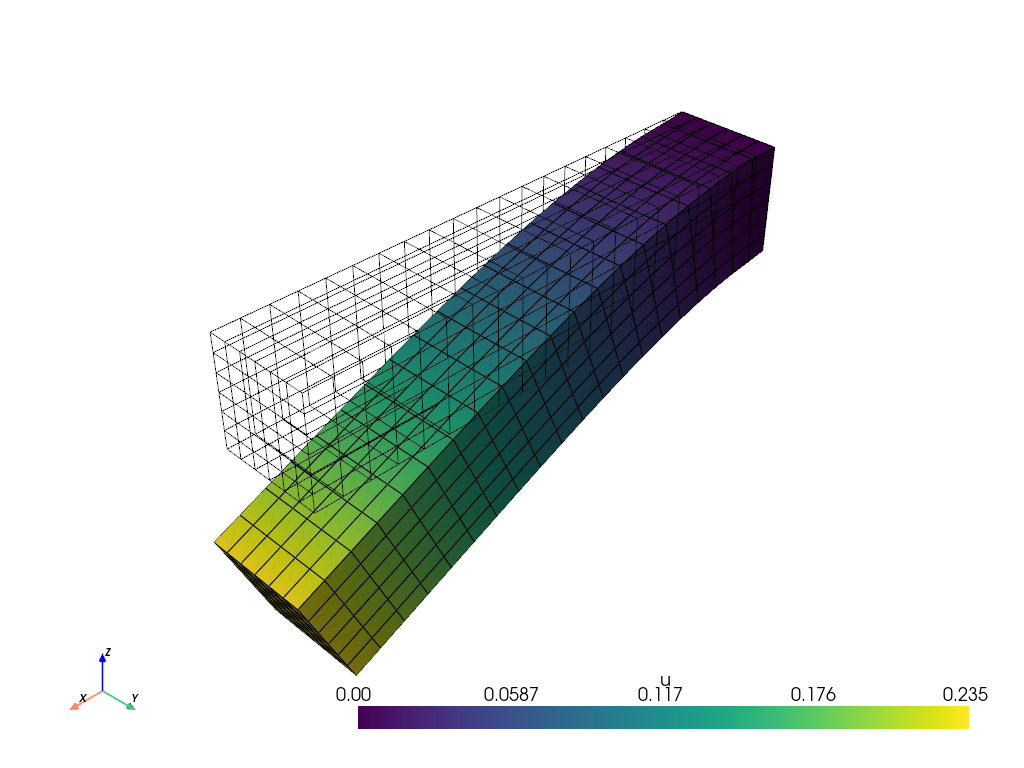

In [5]:
# Create pyvista grid
topology, cell_types, geometry = plot.vtk_mesh(V)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)

# Attach vector values to grid and warp grid by vector
grid["u"] = uh.x.array.reshape((geometry.shape[0], 3))

root = 0
assert root < domain.comm.size, f"Cannot gather on process {root} of {domain.comm.size}"

pieces = domain.comm.gather(grid, root=root)

if pieces is not None:
    merged_grid = pyvista.merge(pieces)
    p = pyvista.Plotter()
    actor_0 = p.add_mesh(merged_grid, style="wireframe", color="k")
    actor_1 = p.add_mesh(merged_grid.warp_by_vector("u", factor=1.5), show_edges=True)
    p.show_axes()
    if not pyvista.OFF_SCREEN:
        p.show()
    else:
        figure_as_array = p.screenshot("deflection.png")

## Stress Computation 
Furthermore, we can compute various stress measures as soon as the displacement is computed. 

von Mises stress is defined by $\boldsymbol{\sigma}_m = \sqrt{\frac{3}{2}\mathbf{s}:\mathbf{s}}$ where $\mathbf{s}$ is the deviatoric stress tensor $\mathbf{s}(\mathbf{u}) = \boldsymbol{\sigma}(\mathbf{u}) - \frac{1}{3}\operatorname{tr}(\boldsymbol{\sigma}(\mathbf{u}))\mathbf{I}$.

The von Mises variable must be projected into an appropriate function space to visualize. 

libEGL warning: egl: failed to create dri2 screen
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card1: Permission denied

2026-10-16 18:34:36.371 ( 593.084s) [    7FF4AD6D3740] vtkEGLRenderWindow.cxx:359   WARN| vtkEGLRenderWindow (0x55a3aabfa650): EGL device index: 0 could not be initialized. Trying other devices...
libEGL warning: egl: failed to create dri2 screen
libEGL warning: egl: failed to create dri2 screen
libEGL warning: failed to open /dev/dri/card1: Permission denied

2026-10-16 18:34:36.508 ( 593.221s) [    7FF4AD6D3740] vtkEGLRenderWindow.cxx:359   WARN| vtkEGLRenderWindow (0x55a3aab2f150): EGL device index: 0 could not be initialized. Trying other devices...
/tmp/ipykernel_4017199/3637824693.py:24: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  p.show(screenshot="stresses.png")
libEGL warning: egl: failed to create dri2 screen
libEGL warning: egl: f

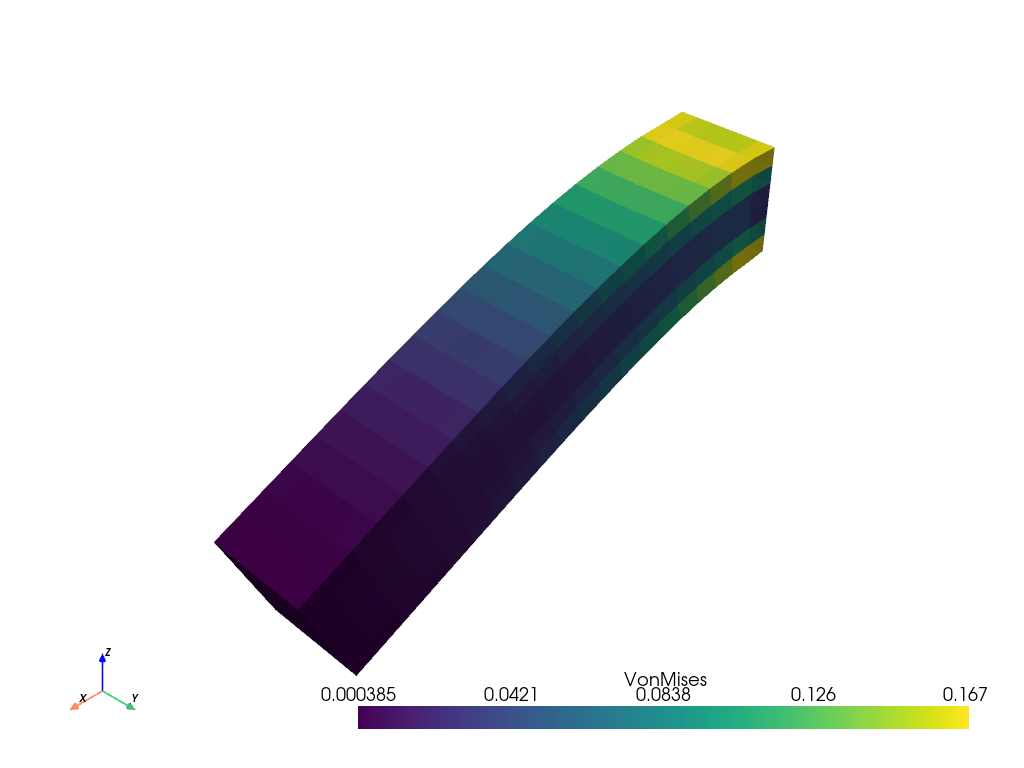

In [8]:
s = sigma(uh) - 1.0 / 3 * ufl.tr(sigma(uh)) * ufl.Identity(len(uh))
von_Mises = ufl.sqrt(3.0 / 2 * ufl.inner(s, s))

V_von_mises = fem.functionspace(domain, ("DG", 0))
stress_expr = fem.Expression(von_Mises, V_von_mises.element.interpolation_points)
stresses = fem.Function(V_von_mises)
stresses.interpolate(stress_expr)

grid.cell_data["VonMises"] = stresses.x.petsc_vec.array
grid.set_active_scalars("VonMises")

stress_clim = [
    domain.comm.reduce(stresses.x.petsc_vec.array.min(), op=MPI.MIN, root=root),
    domain.comm.reduce(stresses.x.petsc_vec.array.max(), op=MPI.MAX, root=root),
]
stress_pieces = domain.comm.gather(grid, root=root)

if stress_pieces is not None:
    merged_stress_grid = pyvista.merge(stress_pieces)
    p = pyvista.Plotter()
    p.add_mesh(merged_stress_grid.warp_by_vector("u", factor=1.5), clim=stress_clim)
    p.show_axes()
    if not pyvista.OFF_SCREEN:
        p.show(screenshot="stresses.png")
    else:
        stress_figure = p.screenshot("stresses.png")